Building parameters and cleaning data

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Bringing in shot data
shots = pd.read_parquet("../data/shots_wc2022.parquet")

In [13]:
# Pitch Coordinates (all shots attack toward x = 120)
PITCH_LENGTH = 120
PITCH_WIDTH = 80
GOAL_X = 120
GOAL_CENTER_Y = 40
GOAL_WIDTH = 8 
POST_LEFT_Y = GOAL_CENTER_Y - GOAL_WIDTH / 2
POST_RIGHT_Y = GOAL_CENTER_Y + GOAL_WIDTH / 2

In [14]:
# Drop penalties - fixed situation so they have a set xG
shots = shots[shots.shot_type != "Penalty"].copy()

In [15]:
# Split [x, y] location into two columns
shots["x"] = shots.location.apply(lambda loc: loc[0])
shots["y"] = shots.location.apply(lambda loc: loc[1])

In [16]:
# Distance and angle to goal
dx = GOAL_X - shots.x
dy = GOAL_CENTER_Y - shots.y

shots["distance"] = np.hypot(dx, dy)
shots["angle"] = np.degrees(np.arctan2(GOAL_WIDTH * dx, dx**2 + dy**2 - GOAL_WIDTH**2))

In [17]:
# Shot details and the target
shots["is_header"] = shots.shot_body_part == "Head"
shots["goal"] = shots.shot_outcome == "Goal"

In [18]:
# Shows data after manipulation/cleaning
# is_header and goal are True/False, 1 for True and 0 for False
shots[["x", "y", "distance", "angle", "is_header", "goal"]].astype(float).describe(include = "all")

,x,y,distance,angle,is_header,goal
count,1430.000000,1430.000000,1430.000000,1430.000000,1430.000000,1430.000000
mean,104.399930,39.847692,18.457459,37.475638,0.176224,0.106294
std,8.263083,9.821709,8.208777,32.261699,0.381144,0.308321
min,59.000000,0.700000,1.315295,0.000000,0.000000,0.000000
25%,98.225000,32.900000,11.907873,17.168876,0.000000,0.000000
50%,105.750000,39.800000,17.809267,24.018463,0.000000,0.000000
75%,111.000000,47.175000,24.479328,45.166330,0.000000,0.000000
max,120.000000,79.200000,70.830784,170.909723,1.000000,1.000000


Goal rate Against Distance

In [19]:
# Grouping shots into distance buckets (yards)
dist_bins = pd.cut(shots.distance, bins = [0, 6, 12, 18, 24, 30, 40, 75])

In [20]:
# Goal rate and number of shots in each bin
rate = shots.groupby(dist_bins, observed = True).goal.agg(["mean", "size"])
rate.columns = ["goal_rate", "shots"]
display(rate)

,goal_rate,shots
distance,,
"(0, 6]",0.440000,50
"(6, 12]",0.191083,314
"(12, 18]",0.125683,366
"(18, 24]",0.047771,314
"(24, 30]",0.023256,258
"(30, 40]",0.024390,123
"(40, 75]",0.000000,5


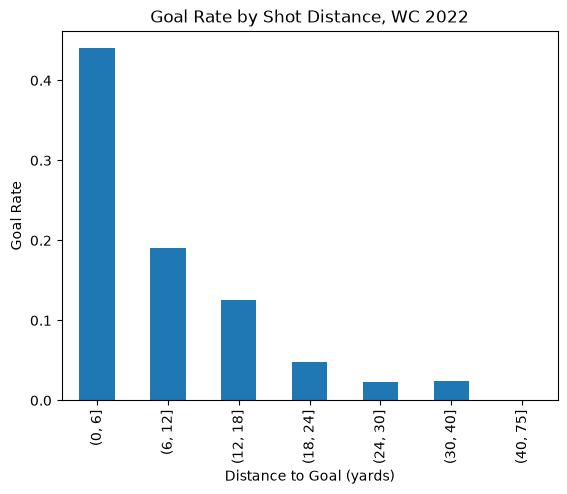

In [21]:
# Goal rate and number of shots plotted
rate.goal_rate.plot(kind = "bar")
plt.xlabel("Distance to Goal (yards)")
plt.ylabel("Goal Rate")
plt.title("Goal Rate by Shot Distance, WC 2022")
plt.show()


In [23]:
# Saving cleaned table
cols = ["match_id", "player", "team", "x", "y", "distance", "angle", "is_header", "goal", "shot_statsbomb_xg"]
shots[cols].to_parquet("../data/shots_features_wc2022.parquet")
